In [ ]:
!pip install -q tensorflow scikit-learn matplotlib seaborn opencv-python-headless

In [ ]:
import os, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import (
    # Makalede kullanılan en iyi 3 model
    Xception, DenseNet121, InceptionV3,
    # Makalede olmayan 3 ekstra model
    EfficientNetB0, VGG16, ResNet50V2
)
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score,
    recall_score, f1_score
)

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
print(f"✅ TensorFlow {tf.__version__} | GPU: {[g.name for g in gpus]}")
print(f"✅ Numpy {np.__version__} | Pandas {pd.__version__}")
if gpus:
    print(f"✅ GPU aktif: {gpus[0].name}")
else:
    print("⚠️  GPU bulunamadı — Çalışma zamanı → GPU (T4) seçin!")

✅ TensorFlow 2.20.0 | GPU: ['/physical_device:GPU:0']
✅ Numpy 2.0.2 | Pandas 2.2.2
✅ GPU aktif: /physical_device:GPU:0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# ─── Proje Yolları ───────────────────────────────────────────
SPLIT_DIR = "/content/drive/MyDrive/Colab Notebooks/Veri/paddydoc_split"
TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR   = os.path.join(SPLIT_DIR, "validation")
TEST_DIR  = os.path.join(SPLIT_DIR, "test")

# ─── Çıktı Klasörleri ────────────────────────────────────────
OUTPUT_DIR  = "/content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1"
MODELS_DIR  = os.path.join(OUTPUT_DIR, "models")
FIGURES_DIR = os.path.join(OUTPUT_DIR, "figures")
RESULTS_DIR = os.path.join(OUTPUT_DIR, "results")

for d in [MODELS_DIR, FIGURES_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

# ─── Hiperparametreler ───────────────────────────────────────
IMG_SIZE    = (256, 256)
BATCH       = 32
CLASS_NAMES = sorted([
    d for d in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, d))
])
NUM_CLASSES = len(CLASS_NAMES)

# ─── Klasör yapısını doğrula ─────────────────────────────────
print("\n📂 Veri Seti Dizin Kontrolü:")
print(f"  SPLIT_DIR mevcut: {os.path.exists(SPLIT_DIR)}")

total_all = 0
for split, path in [("train", TRAIN_DIR), ("validation", VAL_DIR), ("test", TEST_DIR)]:
    split_total = 0
    print(f"\n  {'='*40}")
    print(f"  {split.upper()}")
    print(f"  {'='*40}")
    for cls in CLASS_NAMES:
        full = os.path.join(path, cls)
        n = len([f for f in os.listdir(full)
                 if f.lower().endswith(('.jpg', '.jpeg', '.png'))]) if os.path.exists(full) else 0
        split_total += n
        print(f"  {cls:<28} {n:>5} görüntü")
    print(f"  {'-'*38}")
    print(f"  {'TOPLAM':<28} {split_total:>5} görüntü")
    total_all += split_total

print(f"\n✅ Genel Toplam: {total_all} görüntü")
print(f"✅ Çıktı klasörü: {OUTPUT_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

📂 Veri Seti Dizin Kontrolü:
  SPLIT_DIR mevcut: True

  TRAIN
  bacterial_leaf_blight          224 görüntü
  bacterial_leaf_streak          224 görüntü
  bacterial_panicle_blight       224 görüntü
  blast                          224 görüntü
  brown_spot                     224 görüntü
  dead_heart                     224 görüntü
  downy_mildew                   224 görüntü
  hispa                          224 görüntü
  normal                         224 görüntü
  tungro                         224 görüntü
  --------------------------------------
  TOPLAM                        2240 görüntü

  VALIDATION
  bacterial_leaf_blight           32 görüntü
  bacterial_leaf_streak           32 görüntü
  bacterial_panicle_blight        32 görüntü
  blast                           32 görüntü
  brown_spot                      32 görüntü
  dead_heart                     

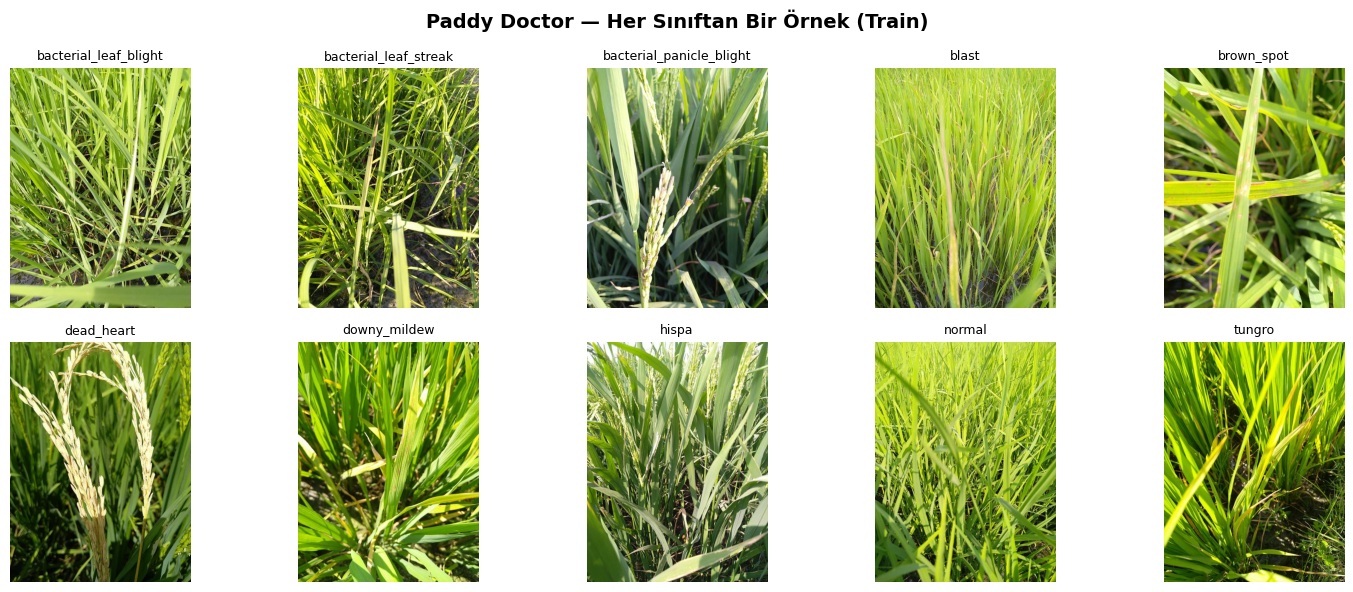

💾 Kaydedildi: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_ornek_goruntuler.png


In [ ]:
import math

cols = 5
rows = math.ceil(NUM_CLASSES / cols)
fig, axes = plt.subplots(rows, cols, figsize=(3*cols, 3*rows))
fig.suptitle("Paddy Doctor — Her Sınıftan Bir Örnek (Train)", fontsize=14, fontweight='bold')
axes = np.array(axes).reshape(-1)

for i, cls in enumerate(CLASS_NAMES):
    cls_path = os.path.join(TRAIN_DIR, cls)
    files = [f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if files:
        img = cv2.imread(os.path.join(cls_path, files[0]))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[i].imshow(img)
    axes[i].set_title(cls, fontsize=9)
    axes[i].axis('off')

for j in range(NUM_CLASSES, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
save_path = os.path.join(FIGURES_DIR, "Yontem1_ornek_goruntuler.png")
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"💾 Kaydedildi: {save_path}")

Found 2240 images belonging to 10 classes.
Found 320 images belonging to 10 classes.
Found 640 images belonging to 10 classes.

✅ Sınıf indeksleri: {'bacterial_leaf_blight': 0, 'bacterial_leaf_streak': 1, 'bacterial_panicle_blight': 2, 'blast': 3, 'brown_spot': 4, 'dead_heart': 5, 'downy_mildew': 6, 'hispa': 7, 'normal': 8, 'tungro': 9}
✅ Adımlar -> Train: 70 | Val: 10 | Test: 20


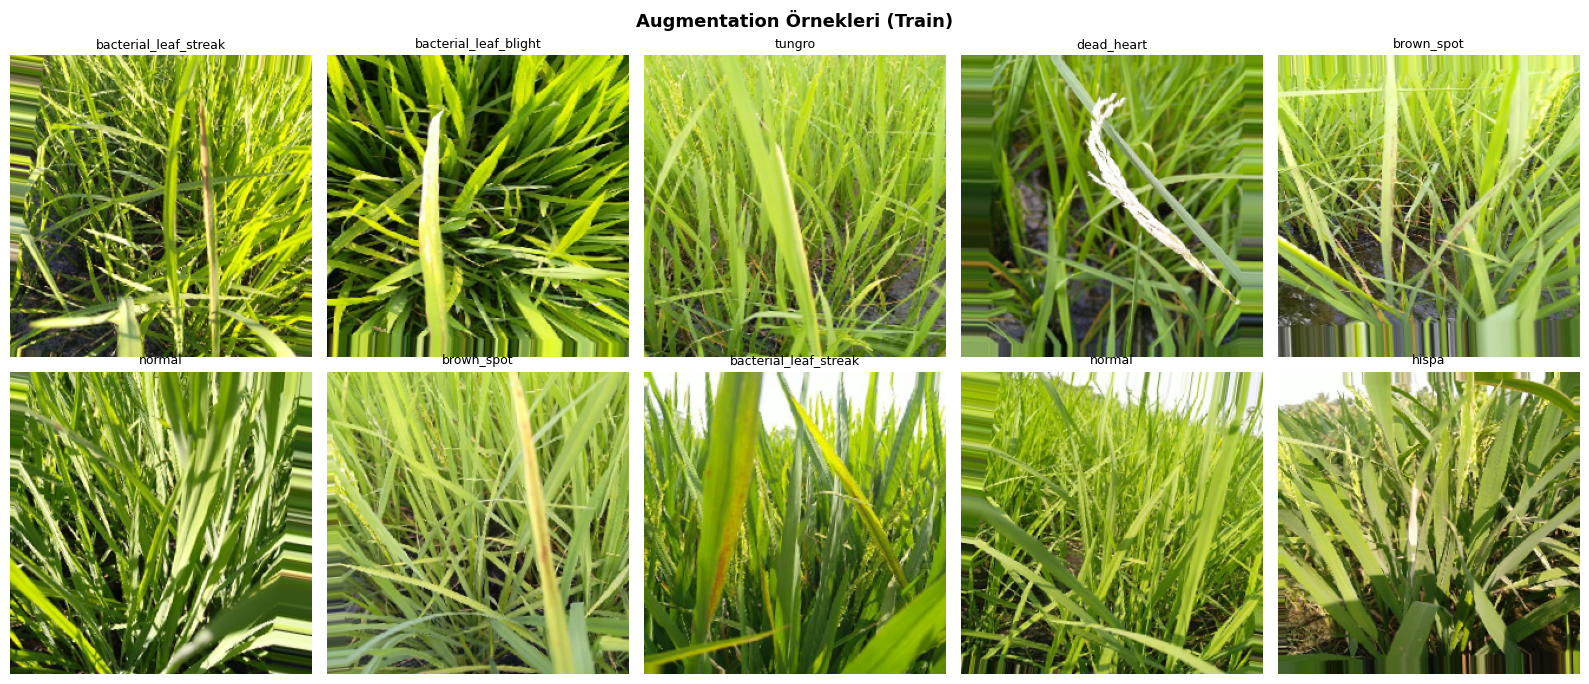

💾 Kaydedildi: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_augmentation_ornekleri.png


In [ ]:
# ─── Train Augmentation (rescale YOK — preprocess modelin içinde) ───────────
train_datagen = ImageDataGenerator(
    rotation_range=10,
    shear_range=0.2,
    zoom_range=0.2,
    width_shift_range=0.05,
    height_shift_range=0.05,
    horizontal_flip=True,
    fill_mode='nearest'
)
# ─── Val / Test: augmentation yok, rescale yok ──────────────────────────────
val_test_datagen = ImageDataGenerator()

def make_gen(datagen, directory, shuffle):
    return datagen.flow_from_directory(
        directory, target_size=IMG_SIZE, batch_size=BATCH,
        class_mode='categorical', classes=CLASS_NAMES, seed=SEED, shuffle=shuffle
    )

train_gen = make_gen(train_datagen,    TRAIN_DIR, True)
val_gen   = make_gen(val_test_datagen, VAL_DIR,   False)
test_gen  = make_gen(val_test_datagen, TEST_DIR,  False)

print(f"\n✅ Sınıf indeksleri: {train_gen.class_indices}")
print(f"✅ Adımlar -> Train: {len(train_gen)} | Val: {len(val_gen)} | Test: {len(test_gen)}")

# ─── Augmentation görsel kontrolü (gösterim için /255) ──────────────────────
sample_batch, sample_labels = next(train_gen)
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
fig.suptitle("Augmentation Örnekleri (Train)", fontsize=13, fontweight='bold')
for i, ax in enumerate(axes.flatten()):
    idx = i % len(sample_batch)
    ax.imshow(np.clip(sample_batch[idx] / 255.0, 0, 1))
    ax.set_title(CLASS_NAMES[np.argmax(sample_labels[idx])], fontsize=9)
    ax.axis('off')
plt.tight_layout()
aug_path = os.path.join(FIGURES_DIR, "Yontem1_augmentation_ornekleri.png")
plt.savefig(aug_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"💾 Kaydedildi: {aug_path}")

In [ ]:
# ─── Eksik mimariler + modele özel ön işleme fonksiyonları ──────────────────
from tensorflow.keras.applications import ResNet101V2, MobileNetV2
from tensorflow.keras.applications import (
    xception, densenet, inception_v3, resnet_v2, mobilenet_v2,
    efficientnet, vgg16
)

BACKBONES = {
    # ── Makalede kullanılan 5 model ──
    'Xception'       : Xception,
    'DenseNet121'    : DenseNet121,
    'InceptionV3'    : InceptionV3,
    'ResNet101V2'    : ResNet101V2,
    'MobileNetV2'    : MobileNetV2,
    # ── Makalede olmayan 3 ekstra model ──
    'EfficientNetB0' : EfficientNetB0,
    'VGG16'          : VGG16,
    'ResNet50V2'     : ResNet50V2,
}
PREPROCESS = {
    'Xception'       : xception.preprocess_input,
    'DenseNet121'    : densenet.preprocess_input,
    'InceptionV3'    : inception_v3.preprocess_input,
    'ResNet101V2'    : resnet_v2.preprocess_input,
    'MobileNetV2'    : mobilenet_v2.preprocess_input,
    'EfficientNetB0' : efficientnet.preprocess_input,   # [0,255] bekler, normalize model içinde
    'VGG16'          : vgg16.preprocess_input,
    'ResNet50V2'     : resnet_v2.preprocess_input,
}
MODEL_NAMES = [
    'Xception', 'DenseNet121', 'InceptionV3', 'ResNet101V2', 'MobileNetV2',  # makale
    'EfficientNetB0', 'VGG16', 'ResNet50V2',                                 # ekstra
]


def build_model(backbone_name, num_classes=None, img_size=None):
    """Ham [0,255] girdi -> modele özel preprocess -> dondurulmuş backbone -> head (128-64-32)."""
    num_classes = num_classes or NUM_CLASSES
    img_size = img_size or IMG_SIZE
    input_shape = (*img_size, 3)

    inputs = keras.Input(shape=input_shape)
    x = layers.Lambda(PREPROCESS[backbone_name], name='preprocess')(inputs)

    base = BACKBONES[backbone_name](include_top=False, weights='imagenet', input_shape=input_shape)
    base.trainable = False
    x = base(x, training=False)

    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    output = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    model = Model(inputs, output, name=backbone_name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model


def get_backbone(model):
    """Modelin içindeki backbone (iç model) katmanını döndürür."""
    for layer in model.layers:
        if isinstance(layer, keras.Model):
            return layer
    return None


# ─── Doğrulama: tüm modeller kuruluyor mu? ──────────────────────────────────
print("🏗️  Model kontrolü:")
for name in MODEL_NAMES:
    m = build_model(name)
    print(f"  ✅ {name:15s} | parametre: {m.count_params():>12,} | backbone: {get_backbone(m).name}")
    del m
    import gc; gc.collect(); keras.backend.clear_session()
print(f"\n✅ Toplam {len(MODEL_NAMES)} model başarıyla kuruldu (5 makale + 3 ekstra).")

🏗️  Model kontrolü:
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
  ✅ Xception        | parametre:   21,142,610 | backbone: xception
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
  ✅ DenseNet121     | parametre:    7,183,466 | backbone: densenet121
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
  ✅ InceptionV3     | parametre:   22,083,914 | backbone: inception_v3
171317808/171317808 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step
  ✅ ResNet101V2     | parametre:   42,907,690 | backbone: resnet101v2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
  ✅ MobileNetV2     | parametre:    2,437,738 | backbone: mobilenetv2_1.00_224
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
  ✅ EfficientNetB0  | parametre:    4,229,325 | backbone: efficientnetb0
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
  ✅ VGG16           | parametre:   14,793,066 | backbone: vgg16
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
  ✅ ResNet50V2      | parametre:   23,845,930 | backbone: resnet50v2

✅ Topla

In [ ]:
def plot_training_curves(history, model_name, save_dir):
    """Train/Val Accuracy ve Loss eğrilerini çizer ve kaydeder."""
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"{model_name} — Eğitim Grafikleri", fontsize=13, fontweight='bold')
    ep = range(1, len(h['accuracy']) + 1)

    axes[0].plot(ep, h['accuracy'],     'b-o', markersize=3, label='Train Accuracy')
    axes[0].plot(ep, h['val_accuracy'], 'r-o', markersize=3, label='Val Accuracy')
    axes[0].set_title('Accuracy vs Epoch'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(ep, h['loss'],     'b-o', markersize=3, label='Train Loss')
    axes[1].plot(ep, h['val_loss'], 'r-o', markersize=3, label='Val Loss')
    axes[1].set_title('Loss vs Epoch'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    fname = os.path.join(save_dir, f"Yontem1_{model_name.lower()}_curves.png")
    plt.savefig(fname, dpi=150, bbox_inches='tight'); plt.show()
    print(f"  💾 Eğitim grafiği: {fname}")


def plot_confusion_matrix(y_true, y_pred, model_name, class_names, save_dir):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(max(8, len(class_names)*0.7), max(7, len(class_names)*0.6)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, linewidths=0.5, ax=ax)
    ax.set_title(f"{model_name} — Confusion Matrix (Test)", fontsize=12, fontweight='bold')
    ax.set_xlabel('Tahmin Edilen'); ax.set_ylabel('Gerçek')
    plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout()
    fname = os.path.join(save_dir, f"Yontem1_{model_name.lower()}_cm.png")
    plt.savefig(fname, dpi=150, bbox_inches='tight'); plt.show()
    print(f"  💾 Confusion matrix: {fname}")
    return cm


def compute_metrics(y_true, y_pred, model_name, elapsed_sec):
    return {
        'Model'                  : model_name,
        'Accuracy'               : round(accuracy_score(y_true, y_pred), 4),
        'Precision'              : round(precision_score(y_true, y_pred, average='macro', zero_division=0), 4),
        'Recall'                 : round(recall_score(y_true, y_pred, average='macro', zero_division=0), 4),
        'F1-score'               : round(f1_score(y_true, y_pred, average='macro', zero_division=0), 4),
        'Train+Test Süresi (sn)' : round(elapsed_sec, 1),
    }

print("✅ Yardımcı fonksiyonlar hazır.")

✅ Yardımcı fonksiyonlar hazır.


In [ ]:
import json, gc
EPOCHS   = 50            # düz 50 epoch (tek aşama, fine-tuning yok)
PATIENCE = 10            # EarlyStopping sabrı

RESULTS_CSV = os.path.join(RESULTS_DIR, "Yontem1_karsilastirma.csv")
HIST_DIR    = os.path.join(OUTPUT_DIR, "histories")
os.makedirs(HIST_DIR, exist_ok=True)

FORCE_RETRAIN = False    # True yaparsan biten modeli de yeniden eğitir

def get_callbacks(model_name):
    ckpt = os.path.join(MODELS_DIR, f"Yontem1_{model_name.lower()}_best.weights.h5")
    cbs = [
        ModelCheckpoint(ckpt, monitor='val_accuracy', save_best_only=True,
                        save_weights_only=True, mode='max', verbose=0),
        EarlyStopping(monitor='val_accuracy', patience=PATIENCE,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=4, min_lr=1e-7, verbose=1),
    ]
    return cbs, ckpt

def reset_generators():
    global train_gen, val_gen, test_gen
    train_gen = make_gen(train_datagen,    TRAIN_DIR, True)
    val_gen   = make_gen(val_test_datagen, VAL_DIR,   False)
    test_gen  = make_gen(val_test_datagen, TEST_DIR,  False)

def save_result_row(row):
    if os.path.exists(RESULTS_CSV):
        df = pd.read_csv(RESULTS_CSV)
        df = df[df['Model'] != row['Model']]          # eski satırı sil, yenisini ekle
        df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    else:
        df = pd.DataFrame([row])
    df.to_csv(RESULTS_CSV, index=False)

def is_done(model_name):
    ckpt = os.path.join(MODELS_DIR, f"Yontem1_{model_name.lower()}_best.weights.h5")
    has_ckpt = os.path.exists(ckpt)
    has_row  = os.path.exists(RESULTS_CSV) and (model_name in pd.read_csv(RESULTS_CSV)['Model'].values)
    return has_ckpt and has_row

def train_one_model(model_name):
    if is_done(model_name) and not FORCE_RETRAIN:
        print(f"⏭️  {model_name} zaten eğitilmiş — atlandı. (Yeniden için FORCE_RETRAIN=True)")
        return
    print("═"*62); print(f"  🏋️  {model_name} — düz {EPOCHS} epoch + EarlyStopping"); print("═"*62)
    reset_generators()
    model = build_model(model_name)
    callbacks, ckpt = get_callbacks(model_name)

    t0 = time.time()
    hist = model.fit(train_gen, epochs=EPOCHS, validation_data=val_gen,
                     callbacks=callbacks, verbose=1)
    if os.path.exists(ckpt):
        model.load_weights(ckpt)            # en iyi ağırlıklar

    test_gen.reset()
    y_proba = model.predict(test_gen, verbose=1)
    elapsed = time.time() - t0              # Train+Test toplam süre
    y_pred  = np.argmax(y_proba, axis=1)
    y_true  = test_gen.classes

    # History'yi Drive'a kaydet (kopma durumunda eğrileri kaybetmemek için)
    with open(os.path.join(HIST_DIR, f"{model_name}.json"), "w") as fo:
        json.dump({k: [float(v) for v in hist.history[k]]
                   for k in ['accuracy','val_accuracy','loss','val_loss']}, fo)

    plot_training_curves(hist, model_name, FIGURES_DIR)
    plot_confusion_matrix(y_true, y_pred, model_name, CLASS_NAMES, FIGURES_DIR)
    print(f"\n  📊 Classification Report — {model_name}:")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

    row = compute_metrics(y_true, y_pred, model_name, elapsed)
    save_result_row(row)
    print(f"  ✅ {model_name} bitti | F1={row['F1-score']} | süre={elapsed:.1f}s → CSV güncellendi")

    del model; gc.collect(); keras.backend.clear_session()

print("✅ Hazır. Modelleri tek tek çalıştır.")
print("   Tamamlananlar:", [m for m in MODEL_NAMES if is_done(m)])

✅ Hazır. Modelleri tek tek çalıştır.
   Tamamlananlar: []


══════════════════════════════════════════════════════════════
  🏋️  Xception — düz 50 epoch + EarlyStopping
══════════════════════════════════════════════════════════════
Found 2240 images belonging to 10 classes.
Found 320 images belonging to 10 classes.
Found 640 images belonging to 10 classes.
Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 1389s 19s/step - accuracy: 0.1420 - loss: 2.4090 - val_accuracy: 0.2438 - val_loss: 2.2494 - learning_rate: 0.0010
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 42s 593ms/step - accuracy: 0.2049 - loss: 2.1866 - val_accuracy: 0.3125 - val_loss: 2.1484 - learning_rate: 0.0010
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 587ms/step - accuracy: 0.2442 - loss: 2.0810 - val_accuracy: 0.3812 - val_loss: 2.0079 - learning_rate: 0.0010
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 39s 552ms/step - accuracy: 0.2714 - loss: 1.9776 - val_accuracy: 0.3812 - val_loss: 1.8779 - learning_rate: 0.0010
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 40s 576ms/step - accuracy: 0.2897 - loss: 1.9484 - 

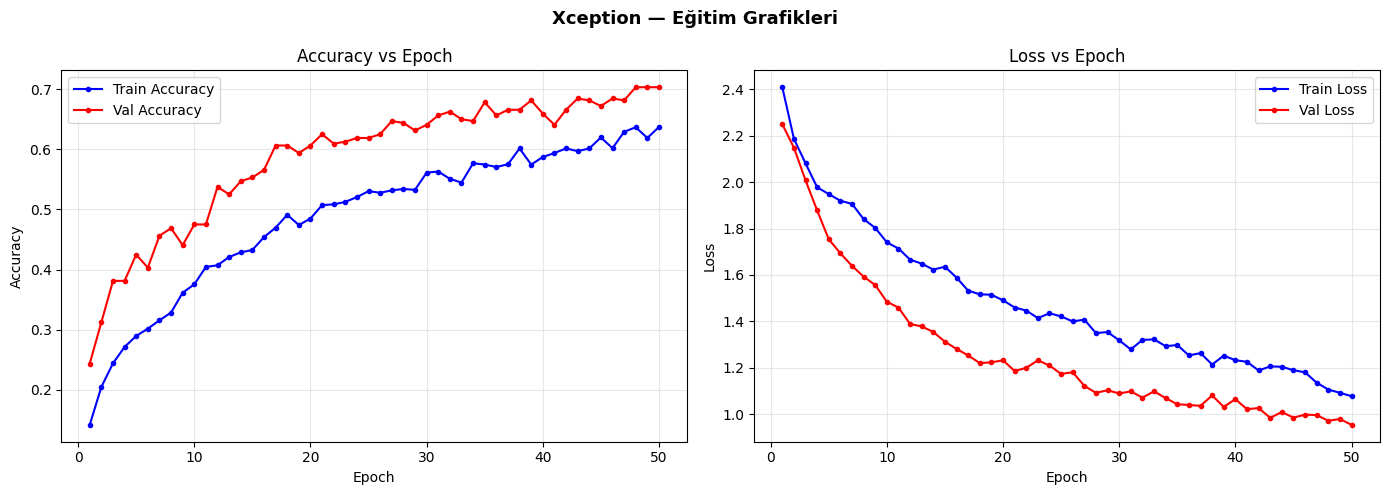

  💾 Eğitim grafiği: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_xception_curves.png


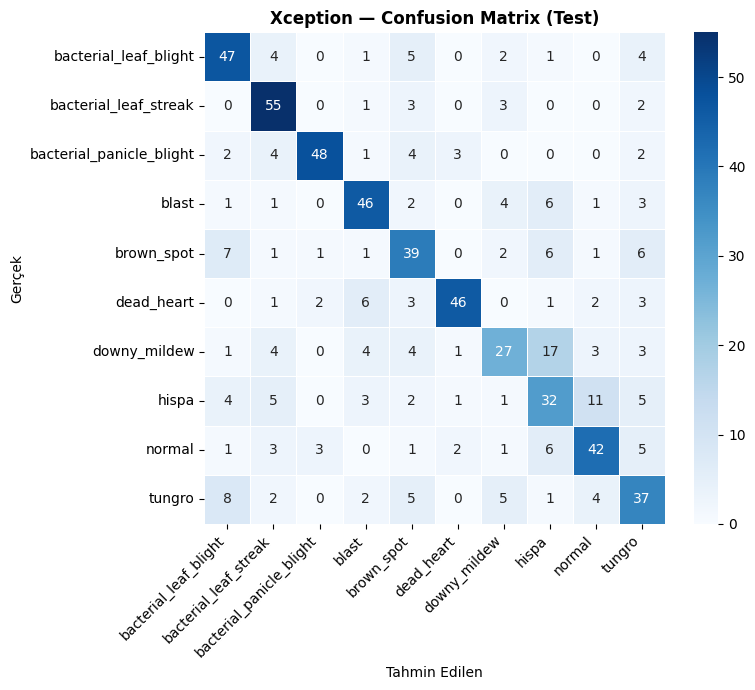

  💾 Confusion matrix: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_xception_cm.png

  📊 Classification Report — Xception:
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.66      0.73      0.70        64
   bacterial_leaf_streak       0.69      0.86      0.76        64
bacterial_panicle_blight       0.89      0.75      0.81        64
                   blast       0.71      0.72      0.71        64
              brown_spot       0.57      0.61      0.59        64
              dead_heart       0.87      0.72      0.79        64
            downy_mildew       0.60      0.42      0.50        64
                   hispa       0.46      0.50      0.48        64
                  normal       0.66      0.66      0.66        64
                  tungro       0.53      0.58      0.55        64

                accuracy                           0.65       640
               macro avg       0.66      0.65    

In [ ]:
train_one_model('Xception')

══════════════════════════════════════════════════════════════
  🏋️  DenseNet121 — düz 50 epoch + EarlyStopping
══════════════════════════════════════════════════════════════
Found 2240 images belonging to 10 classes.
Found 320 images belonging to 10 classes.
Found 640 images belonging to 10 classes.
Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 88s 774ms/step - accuracy: 0.1714 - loss: 2.2929 - val_accuracy: 0.3063 - val_loss: 2.1253 - learning_rate: 0.0010
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 585ms/step - accuracy: 0.2652 - loss: 2.0280 - val_accuracy: 0.3656 - val_loss: 1.8971 - learning_rate: 0.0010
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 581ms/step - accuracy: 0.3330 - loss: 1.8634 - val_accuracy: 0.4375 - val_loss: 1.6919 - learning_rate: 0.0010
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 584ms/step - accuracy: 0.3911 - loss: 1.7409 - val_accuracy: 0.4969 - val_loss: 1.5298 - learning_rate: 0.0010
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 38s 547ms/step - accuracy: 0.4112 - loss: 1.6634

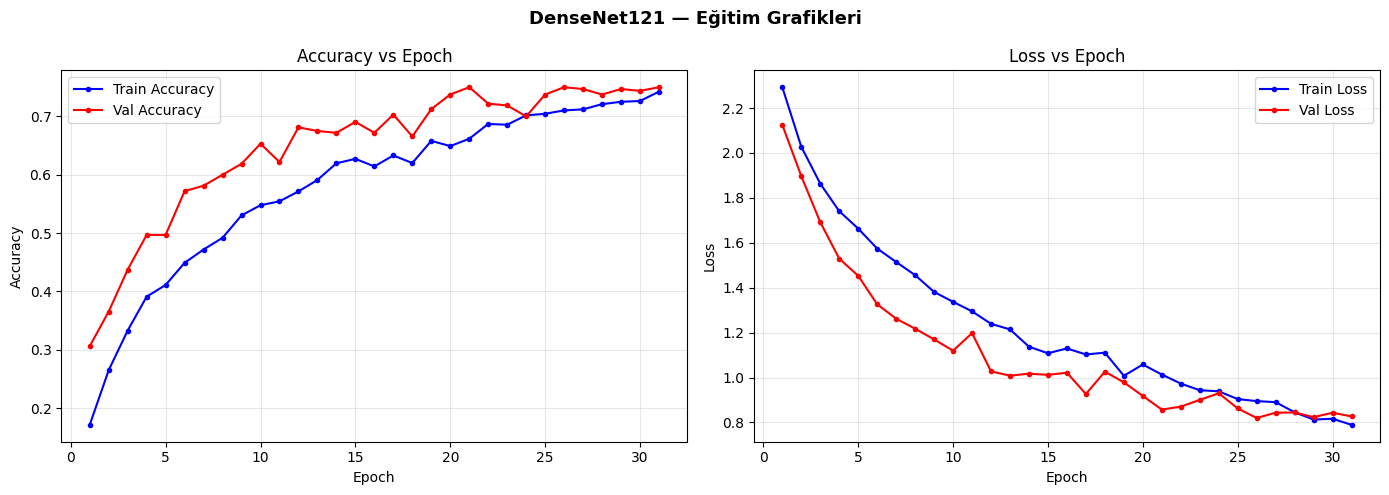

  💾 Eğitim grafiği: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_densenet121_curves.png


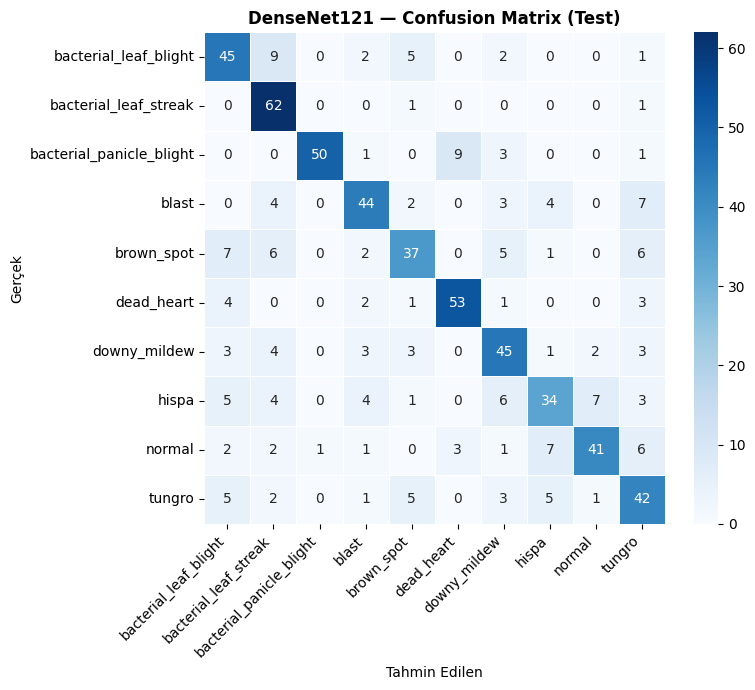

  💾 Confusion matrix: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_densenet121_cm.png

  📊 Classification Report — DenseNet121:
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.63      0.70      0.67        64
   bacterial_leaf_streak       0.67      0.97      0.79        64
bacterial_panicle_blight       0.98      0.78      0.87        64
                   blast       0.73      0.69      0.71        64
              brown_spot       0.67      0.58      0.62        64
              dead_heart       0.82      0.83      0.82        64
            downy_mildew       0.65      0.70      0.68        64
                   hispa       0.65      0.53      0.59        64
                  normal       0.80      0.64      0.71        64
                  tungro       0.58      0.66      0.61        64

                accuracy                           0.71       640
               macro avg       0.72      0.

In [ ]:
train_one_model('DenseNet121')

══════════════════════════════════════════════════════════════
  🏋️  InceptionV3 — düz 50 epoch + EarlyStopping
══════════════════════════════════════════════════════════════
Found 2240 images belonging to 10 classes.
Found 320 images belonging to 10 classes.
Found 640 images belonging to 10 classes.
Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 73s 782ms/step - accuracy: 0.1625 - loss: 2.4605 - val_accuracy: 0.2750 - val_loss: 2.1744 - learning_rate: 0.0010
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 42s 595ms/step - accuracy: 0.2210 - loss: 2.1940 - val_accuracy: 0.3688 - val_loss: 2.0251 - learning_rate: 0.0010
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 583ms/step - accuracy: 0.2652 - loss: 2.0759 - val_accuracy: 0.3844 - val_loss: 1.9014 - learning_rate: 0.0010
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 587ms/step - accuracy: 0.3067 - loss: 1.9769 - val_accuracy: 0.4531 - val_loss: 1.7682 - learning_rate: 0.0010
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 589ms/step - accuracy: 0.3362 - loss: 1.8696

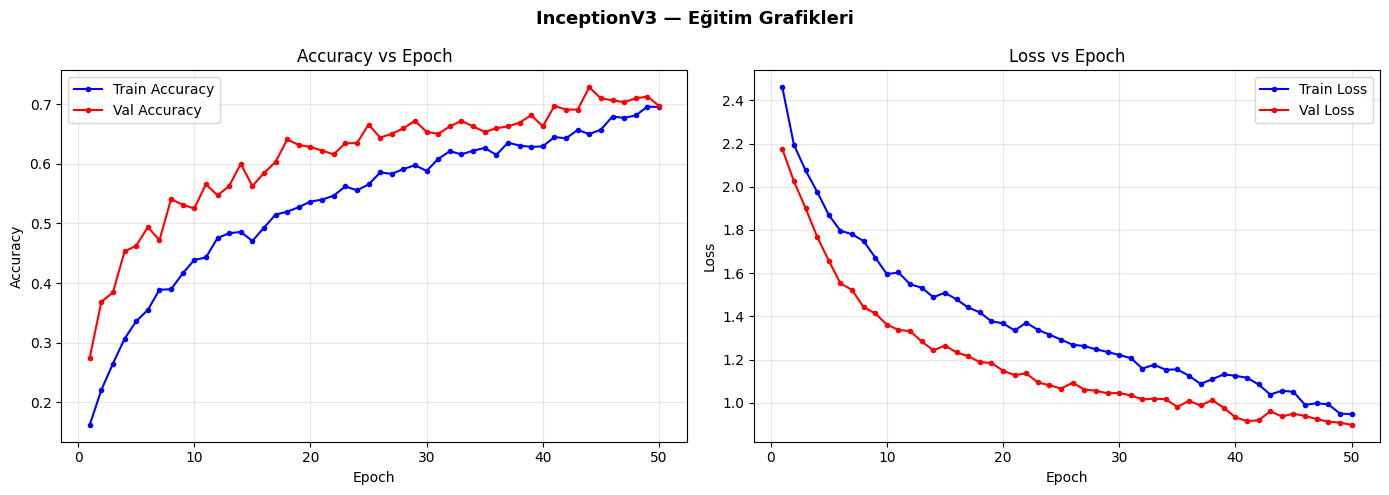

  💾 Eğitim grafiği: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_inceptionv3_curves.png


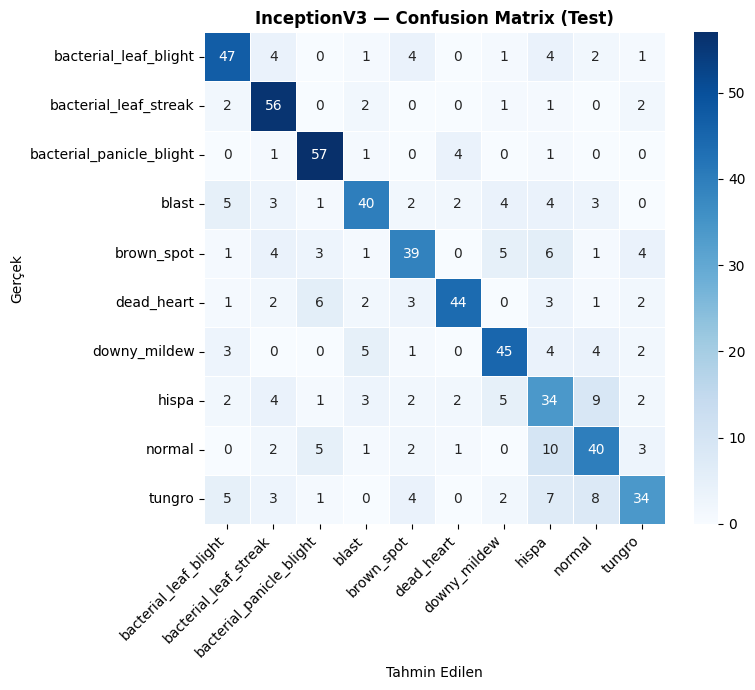

  💾 Confusion matrix: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_inceptionv3_cm.png

  📊 Classification Report — InceptionV3:
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.71      0.73      0.72        64
   bacterial_leaf_streak       0.71      0.88      0.78        64
bacterial_panicle_blight       0.77      0.89      0.83        64
                   blast       0.71      0.62      0.67        64
              brown_spot       0.68      0.61      0.64        64
              dead_heart       0.83      0.69      0.75        64
            downy_mildew       0.71      0.70      0.71        64
                   hispa       0.46      0.53      0.49        64
                  normal       0.59      0.62      0.61        64
                  tungro       0.68      0.53      0.60        64

                accuracy                           0.68       640
               macro avg       0.69      0.

In [ ]:
train_one_model('InceptionV3')

══════════════════════════════════════════════════════════════
  🏋️  ResNet101V2 — düz 50 epoch + EarlyStopping
══════════════════════════════════════════════════════════════
Found 2240 images belonging to 10 classes.
Found 320 images belonging to 10 classes.
Found 640 images belonging to 10 classes.
Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 75s 771ms/step - accuracy: 0.1558 - loss: 2.3932 - val_accuracy: 0.3094 - val_loss: 2.0794 - learning_rate: 0.0010
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 625ms/step - accuracy: 0.2451 - loss: 2.1007 - val_accuracy: 0.4219 - val_loss: 1.9013 - learning_rate: 0.0010
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 43s 622ms/step - accuracy: 0.3004 - loss: 1.9747 - val_accuracy: 0.4406 - val_loss: 1.7821 - learning_rate: 0.0010
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 43s 616ms/step - accuracy: 0.3402 - loss: 1.8689 - val_accuracy: 0.5063 - val_loss: 1.6315 - learning_rate: 0.0010
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 40s 568ms/step - accuracy: 0.3750 - loss: 1.8011

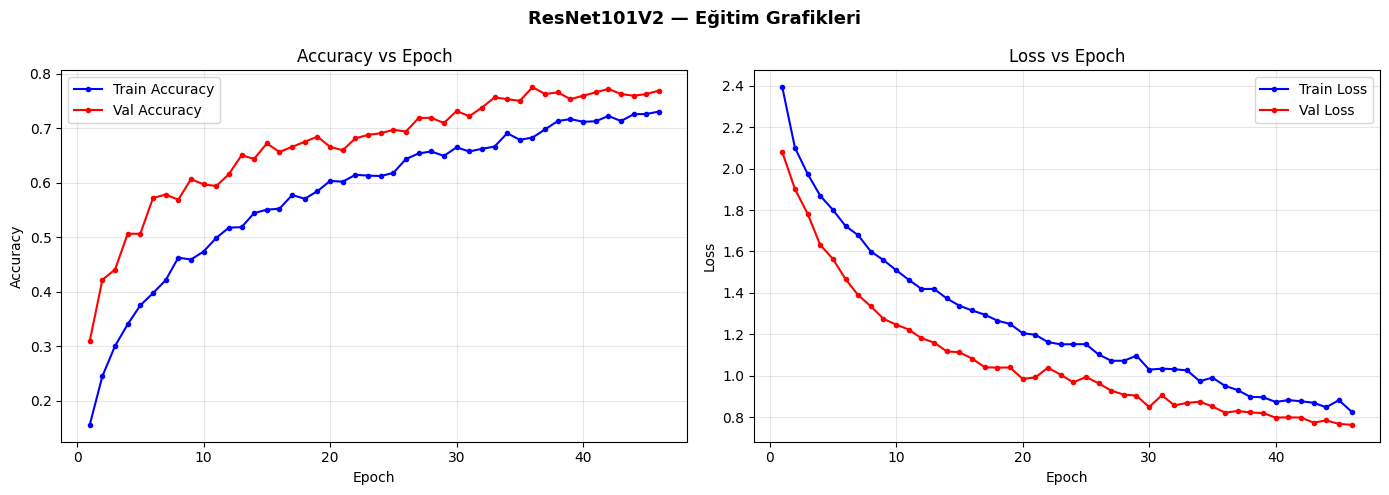

  💾 Eğitim grafiği: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_resnet101v2_curves.png


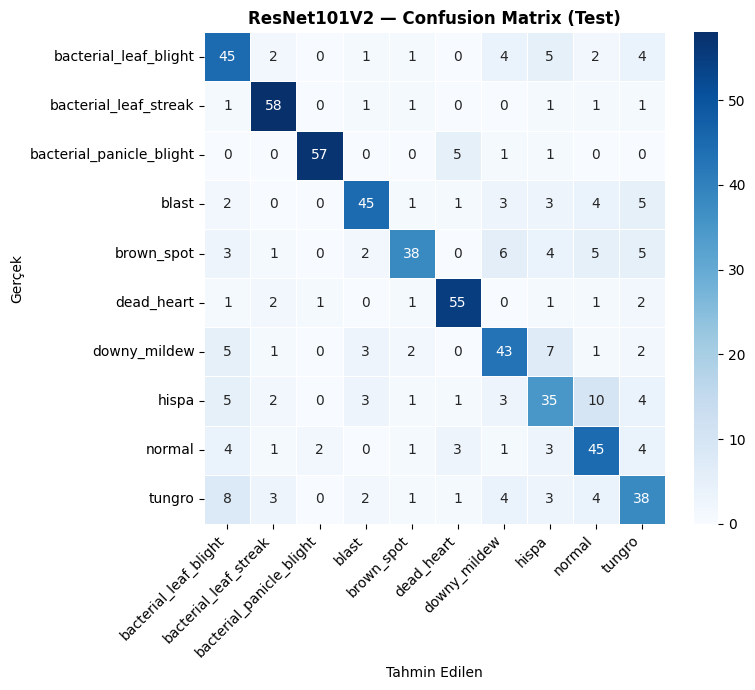

  💾 Confusion matrix: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_resnet101v2_cm.png

  📊 Classification Report — ResNet101V2:
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.61      0.70      0.65        64
   bacterial_leaf_streak       0.83      0.91      0.87        64
bacterial_panicle_blight       0.95      0.89      0.92        64
                   blast       0.79      0.70      0.74        64
              brown_spot       0.81      0.59      0.68        64
              dead_heart       0.83      0.86      0.85        64
            downy_mildew       0.66      0.67      0.67        64
                   hispa       0.56      0.55      0.55        64
                  normal       0.62      0.70      0.66        64
                  tungro       0.58      0.59      0.59        64

                accuracy                           0.72       640
               macro avg       0.72      0.

In [ ]:
train_one_model('ResNet101V2')

══════════════════════════════════════════════════════════════
  🏋️  MobileNetV2 — düz 50 epoch + EarlyStopping
══════════════════════════════════════════════════════════════
Found 2240 images belonging to 10 classes.
Found 320 images belonging to 10 classes.
Found 640 images belonging to 10 classes.
Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 75s 663ms/step - accuracy: 0.1531 - loss: 2.3600 - val_accuracy: 0.2719 - val_loss: 2.1604 - learning_rate: 0.0010
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 40s 567ms/step - accuracy: 0.2629 - loss: 2.0513 - val_accuracy: 0.3719 - val_loss: 1.9411 - learning_rate: 0.0010
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 40s 565ms/step - accuracy: 0.3210 - loss: 1.9137 - val_accuracy: 0.4313 - val_loss: 1.8052 - learning_rate: 0.0010
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 40s 566ms/step - accuracy: 0.3562 - loss: 1.8358 - val_accuracy: 0.4688 - val_loss: 1.7056 - learning_rate: 0.0010
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 39s 558ms/step - accuracy: 0.4040 - loss: 1.7420

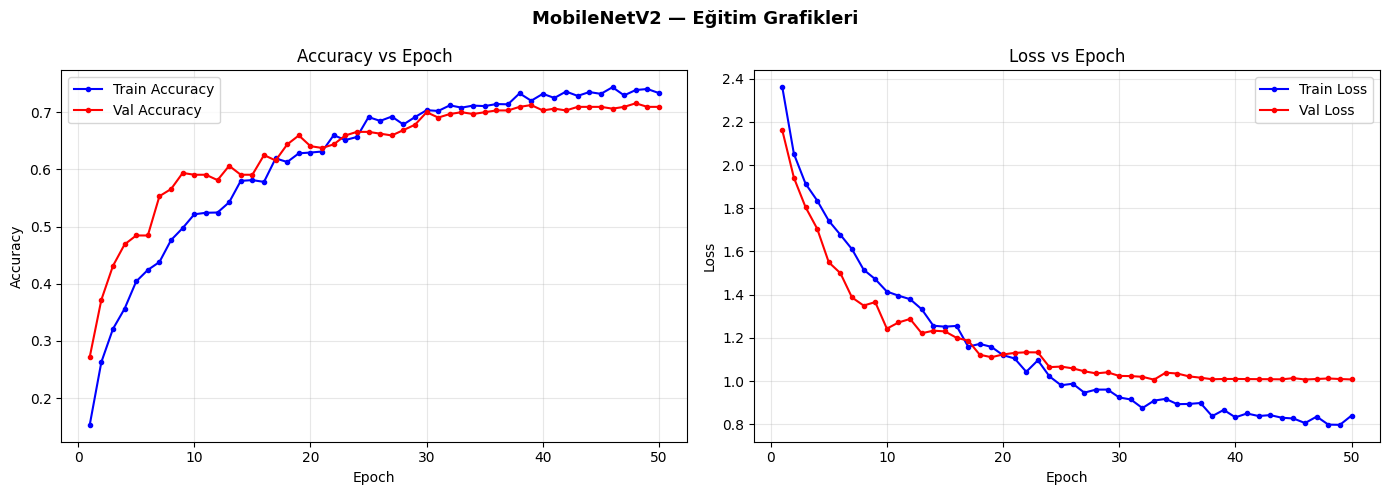

  💾 Eğitim grafiği: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_mobilenetv2_curves.png


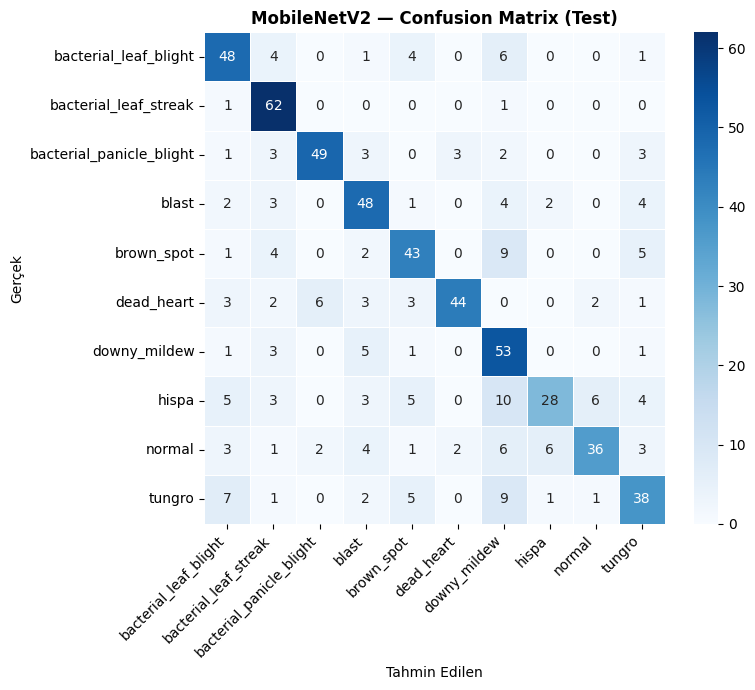

  💾 Confusion matrix: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_mobilenetv2_cm.png

  📊 Classification Report — MobileNetV2:
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.67      0.75      0.71        64
   bacterial_leaf_streak       0.72      0.97      0.83        64
bacterial_panicle_blight       0.86      0.77      0.81        64
                   blast       0.68      0.75      0.71        64
              brown_spot       0.68      0.67      0.68        64
              dead_heart       0.90      0.69      0.78        64
            downy_mildew       0.53      0.83      0.65        64
                   hispa       0.76      0.44      0.55        64
                  normal       0.80      0.56      0.66        64
                  tungro       0.63      0.59      0.61        64

                accuracy                           0.70       640
               macro avg       0.72      0.

In [ ]:
train_one_model('MobileNetV2')

══════════════════════════════════════════════════════════════
  🏋️  EfficientNetB0 — düz 50 epoch + EarlyStopping
══════════════════════════════════════════════════════════════
Found 2240 images belonging to 10 classes.
Found 320 images belonging to 10 classes.
Found 640 images belonging to 10 classes.
Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 82s 694ms/step - accuracy: 0.1688 - loss: 2.3723 - val_accuracy: 0.3313 - val_loss: 2.1480 - learning_rate: 0.0010
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 40s 577ms/step - accuracy: 0.2737 - loss: 2.0187 - val_accuracy: 0.4062 - val_loss: 1.9681 - learning_rate: 0.0010
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 40s 571ms/step - accuracy: 0.3290 - loss: 1.8651 - val_accuracy: 0.4688 - val_loss: 1.7856 - learning_rate: 0.0010
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 40s 572ms/step - accuracy: 0.3688 - loss: 1.7496 - val_accuracy: 0.4906 - val_loss: 1.6136 - learning_rate: 0.0010
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 40s 570ms/step - accuracy: 0.4022 - loss: 1.6

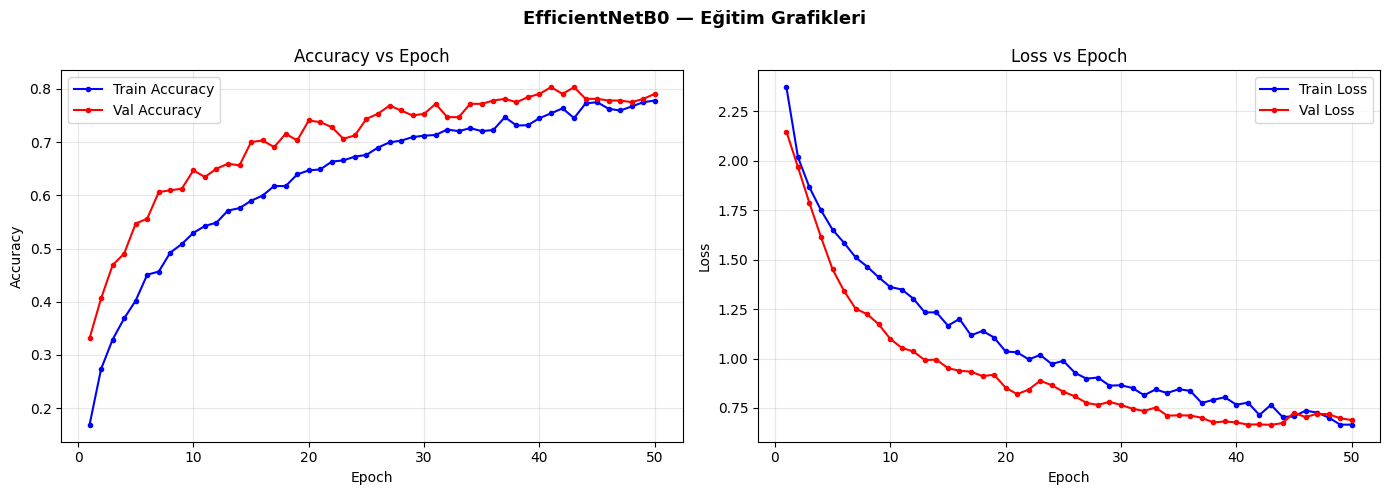

  💾 Eğitim grafiği: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_efficientnetb0_curves.png


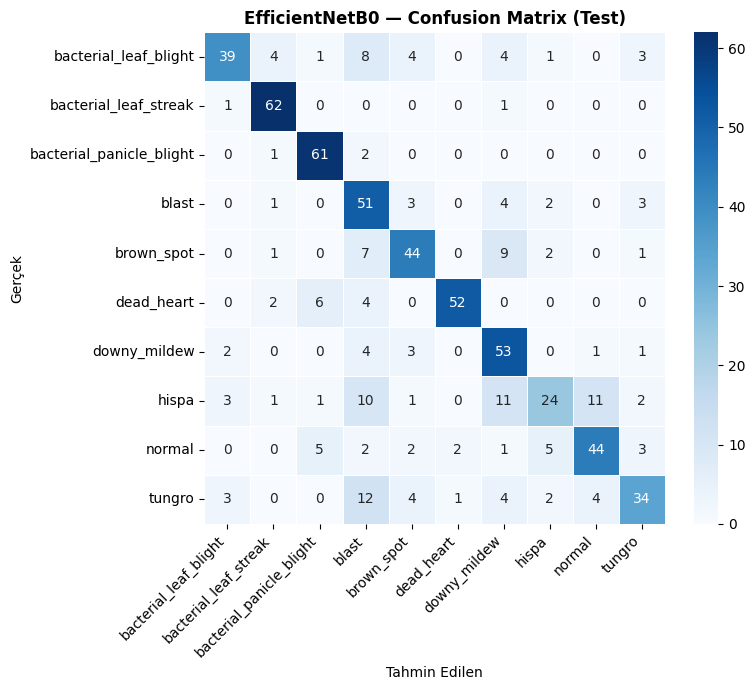

  💾 Confusion matrix: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_efficientnetb0_cm.png

  📊 Classification Report — EfficientNetB0:
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.81      0.61      0.70        64
   bacterial_leaf_streak       0.86      0.97      0.91        64
bacterial_panicle_blight       0.82      0.95      0.88        64
                   blast       0.51      0.80      0.62        64
              brown_spot       0.72      0.69      0.70        64
              dead_heart       0.95      0.81      0.87        64
            downy_mildew       0.61      0.83      0.70        64
                   hispa       0.67      0.38      0.48        64
                  normal       0.73      0.69      0.71        64
                  tungro       0.72      0.53      0.61        64

                accuracy                           0.72       640
               macro avg       0.74  

In [ ]:
train_one_model('EfficientNetB0')

══════════════════════════════════════════════════════════════
  🏋️  VGG16 — düz 50 epoch + EarlyStopping
══════════════════════════════════════════════════════════════
Found 2240 images belonging to 10 classes.
Found 320 images belonging to 10 classes.
Found 640 images belonging to 10 classes.
Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 55s 617ms/step - accuracy: 0.1147 - loss: 2.4439 - val_accuracy: 0.1656 - val_loss: 2.2382 - learning_rate: 0.0010
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 586ms/step - accuracy: 0.1549 - loss: 2.2678 - val_accuracy: 0.2625 - val_loss: 2.1312 - learning_rate: 0.0010
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 583ms/step - accuracy: 0.1978 - loss: 2.1977 - val_accuracy: 0.3250 - val_loss: 1.9832 - learning_rate: 0.0010
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 40s 575ms/step - accuracy: 0.2339 - loss: 2.1220 - val_accuracy: 0.3313 - val_loss: 1.9087 - learning_rate: 0.0010
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 40s 568ms/step - accuracy: 0.2634 - loss: 2.0433 - val

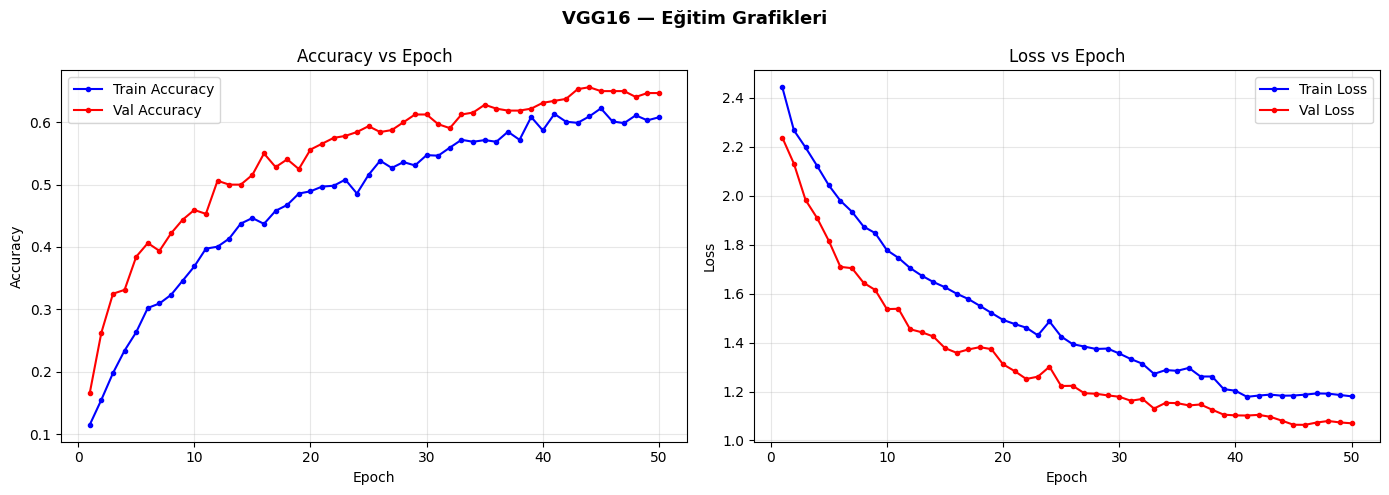

  💾 Eğitim grafiği: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_vgg16_curves.png


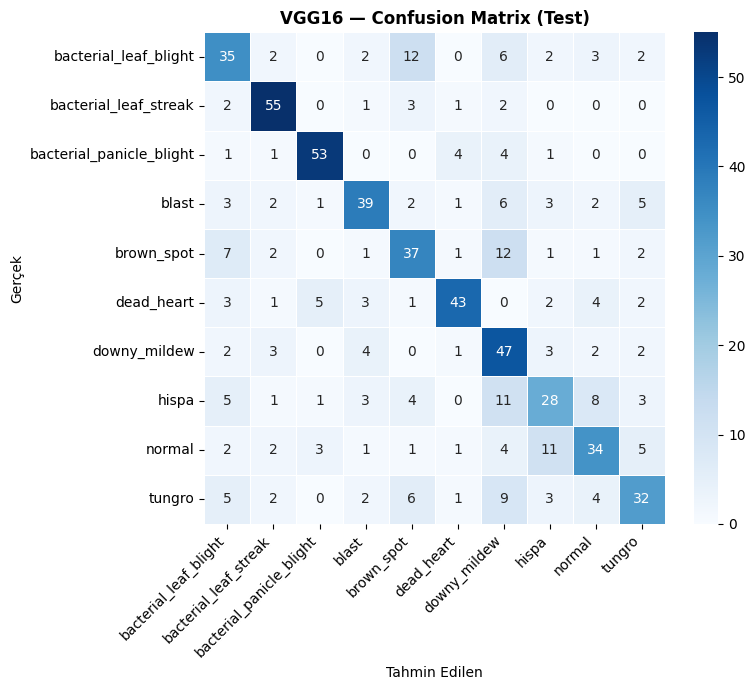

  💾 Confusion matrix: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_vgg16_cm.png

  📊 Classification Report — VGG16:
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.54      0.55      0.54        64
   bacterial_leaf_streak       0.77      0.86      0.81        64
bacterial_panicle_blight       0.84      0.83      0.83        64
                   blast       0.70      0.61      0.65        64
              brown_spot       0.56      0.58      0.57        64
              dead_heart       0.81      0.67      0.74        64
            downy_mildew       0.47      0.73      0.57        64
                   hispa       0.52      0.44      0.47        64
                  normal       0.59      0.53      0.56        64
                  tungro       0.60      0.50      0.55        64

                accuracy                           0.63       640
               macro avg       0.64      0.63      0.63

In [ ]:
train_one_model('VGG16')

══════════════════════════════════════════════════════════════
  🏋️  ResNet50V2 — düz 50 epoch + EarlyStopping
══════════════════════════════════════════════════════════════
Found 2240 images belonging to 10 classes.
Found 320 images belonging to 10 classes.
Found 640 images belonging to 10 classes.
Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 55s 615ms/step - accuracy: 0.1589 - loss: 2.3592 - val_accuracy: 0.2688 - val_loss: 2.1981 - learning_rate: 0.0010
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 42s 593ms/step - accuracy: 0.2192 - loss: 2.1342 - val_accuracy: 0.3938 - val_loss: 2.0366 - learning_rate: 0.0010
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 584ms/step - accuracy: 0.2884 - loss: 2.0118 - val_accuracy: 0.4531 - val_loss: 1.8345 - learning_rate: 0.0010
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 586ms/step - accuracy: 0.3384 - loss: 1.8795 - val_accuracy: 0.4906 - val_loss: 1.6328 - learning_rate: 0.0010
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 587ms/step - accuracy: 0.3821 - loss: 1.7692 

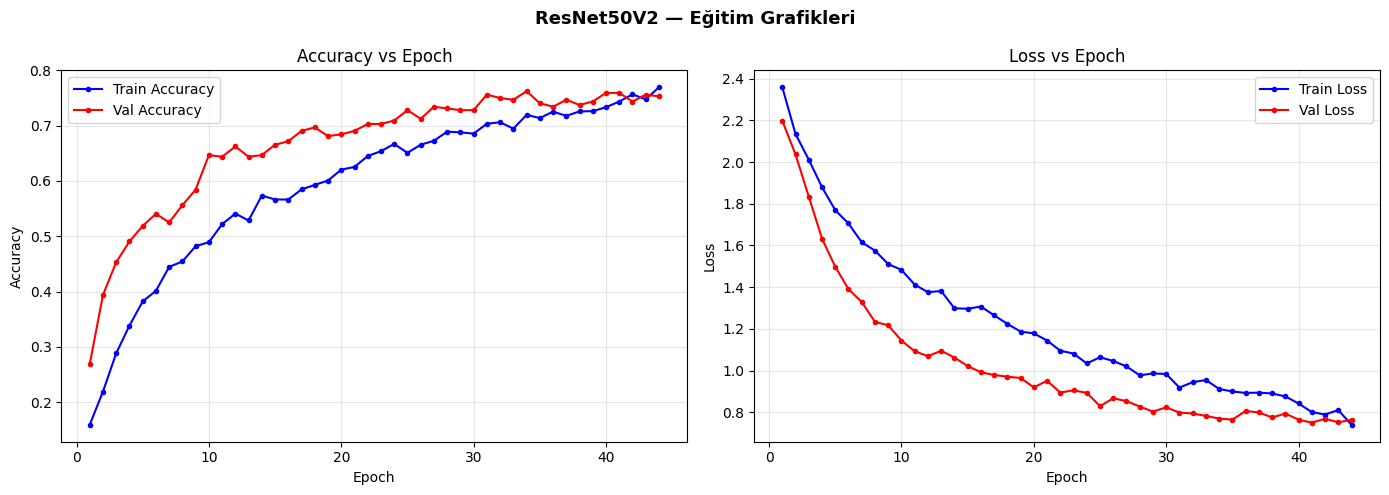

  💾 Eğitim grafiği: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_resnet50v2_curves.png


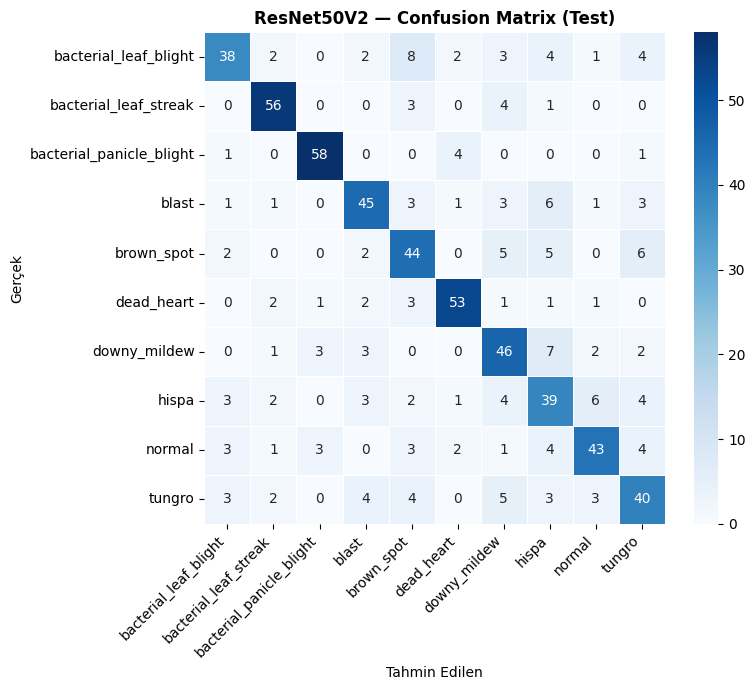

  💾 Confusion matrix: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_resnet50v2_cm.png

  📊 Classification Report — ResNet50V2:
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.75      0.59      0.66        64
   bacterial_leaf_streak       0.84      0.88      0.85        64
bacterial_panicle_blight       0.89      0.91      0.90        64
                   blast       0.74      0.70      0.72        64
              brown_spot       0.63      0.69      0.66        64
              dead_heart       0.84      0.83      0.83        64
            downy_mildew       0.64      0.72      0.68        64
                   hispa       0.56      0.61      0.58        64
                  normal       0.75      0.67      0.71        64
                  tungro       0.62      0.62      0.62        64

                accuracy                           0.72       640
               macro avg       0.73      0.72

In [ ]:
train_one_model('ResNet50V2')

════════════════════════════════════════════════════════════════════════════════
  📊 KARŞILAŞTIRMA TABLOSU
════════════════════════════════════════════════════════════════════════════════
            Model  Accuracy  Precision  Recall  F1-score  Train+Test Süresi (sn)
1      ResNet50V2    0.7219     0.7256  0.7219    0.7221                  1762.4
2  EfficientNetB0    0.7250     0.7407  0.7250    0.7196                  2009.1
3     ResNet101V2    0.7172     0.7236  0.7172    0.7176                  1903.9
4     DenseNet121    0.7078     0.7188  0.7078    0.7068                  1298.6
5     MobileNetV2    0.7016     0.7224  0.7016    0.6984                  1972.5
6     InceptionV3    0.6813     0.6862  0.6813    0.6800                  2006.0
7        Xception    0.6547     0.6629  0.6547    0.6546                  3763.0
8           VGG16    0.6297     0.6397  0.6297    0.6295                  1975.2

🏆 En İyi: ResNet50V2 (F1=0.7221)


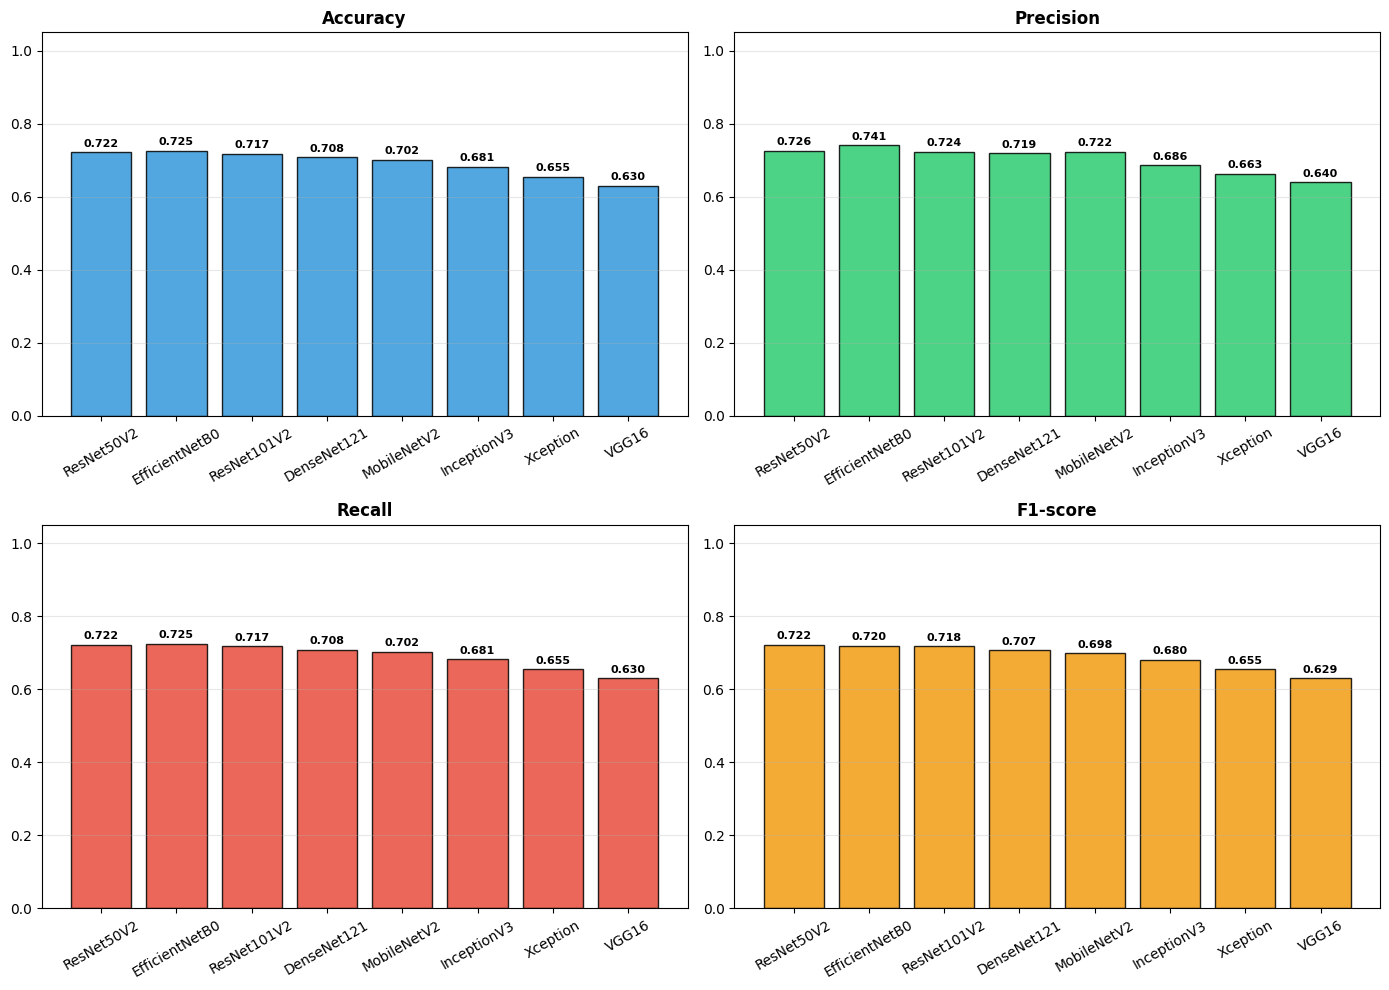

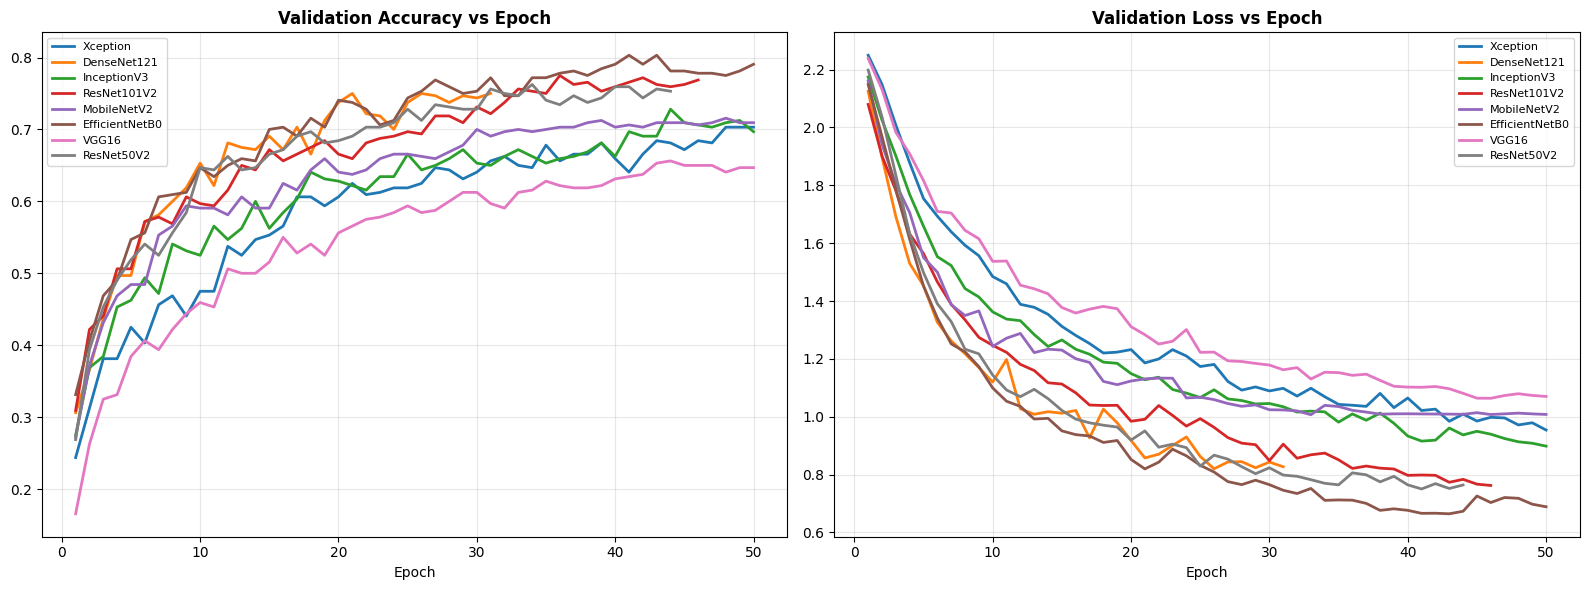

Found 2240 images belonging to 10 classes.
Found 320 images belonging to 10 classes.
Found 640 images belonging to 10 classes.
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 147ms/step


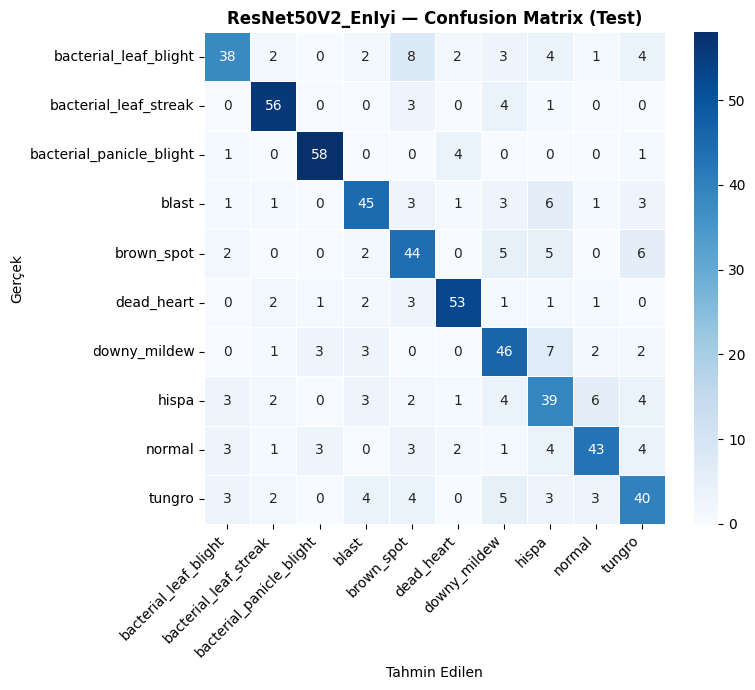

  💾 Confusion matrix: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/figures/Yontem1_resnet50v2_eniyi_cm.png
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.75      0.59      0.66        64
   bacterial_leaf_streak       0.84      0.88      0.85        64
bacterial_panicle_blight       0.89      0.91      0.90        64
                   blast       0.74      0.70      0.72        64
              brown_spot       0.63      0.69      0.66        64
              dead_heart       0.84      0.83      0.83        64
            downy_mildew       0.64      0.72      0.68        64
                   hispa       0.56      0.61      0.58        64
                  normal       0.75      0.67      0.71        64
                  tungro       0.62      0.62      0.62        64

                accuracy                           0.72       640
               macro avg       0.73      0.72      0.72       640
            we

In [ ]:
import json
results_df = pd.read_csv(RESULTS_CSV).sort_values('F1-score', ascending=False).reset_index(drop=True)
results_df.index += 1
best_model_name = results_df.iloc[0]['Model']
best_f1 = results_df.iloc[0]['F1-score']

print("═"*80); print("  📊 KARŞILAŞTIRMA TABLOSU"); print("═"*80)
print(results_df.to_string())
print(f"\n🏆 En İyi: {best_model_name} (F1={best_f1:.4f})")

# Bar grafikleri
metrics = ['Accuracy','Precision','Recall','F1-score']; colors=['#3498db','#2ecc71','#e74c3c','#f39c12']
fig, axes = plt.subplots(2,2, figsize=(14,10))
for idx,(m,c) in enumerate(zip(metrics,colors)):
    ax=axes[idx//2][idx%2]
    bars=ax.bar(results_df['Model'], results_df[m], color=c, alpha=0.85, edgecolor='black')
    ax.set_title(m, fontweight='bold'); ax.set_ylim(0,1.05); ax.tick_params(axis='x', rotation=30); ax.grid(axis='y', alpha=0.3)
    for b in bars: ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.01, f"{b.get_height():.3f}", ha='center', va='bottom', fontsize=8, fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR,"Yontem1_metrik_barlar.png"), dpi=150, bbox_inches='tight'); plt.show()

# Tüm modeller validation eğrileri (Drive'daki history json'larından)
fig, axes = plt.subplots(1,2, figsize=(16,6))
for m in MODEL_NAMES:
    hp = os.path.join(HIST_DIR, f"{m}.json")
    if not os.path.exists(hp): continue
    h = json.load(open(hp)); ep = range(1, len(h['val_accuracy'])+1)
    axes[0].plot(ep, h['val_accuracy'], linewidth=2, label=m)
    axes[1].plot(ep, h['val_loss'], linewidth=2, label=m)
axes[0].set_title('Validation Accuracy vs Epoch', fontweight='bold'); axes[0].set_xlabel('Epoch'); axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)
axes[1].set_title('Validation Loss vs Epoch', fontweight='bold'); axes[1].set_xlabel('Epoch'); axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR,"Yontem1_tum_val_curves.png"), dpi=150, bbox_inches='tight'); plt.show()

# En iyi model — Confusion Matrix
best_ckpt = os.path.join(MODELS_DIR, f"Yontem1_{best_model_name.lower()}_best.weights.h5")
best_model = build_model(best_model_name)
best_model.load_weights(best_ckpt)
reset_generators(); test_gen.reset()
y_pred_best = np.argmax(best_model.predict(test_gen, verbose=1), axis=1)
plot_confusion_matrix(test_gen.classes, y_pred_best, f"{best_model_name}_EnIyi", CLASS_NAMES, FIGURES_DIR)
print(classification_report(test_gen.classes, y_pred_best, target_names=CLASS_NAMES, zero_division=0))
del best_model; gc.collect(); keras.backend.clear_session()